# Análisis de los entrenamientos con validación interna

Este notebook resume todos los runs terminados de `runs/` a partir de los ficheros que escribe cada entrenamiento (`history.csv`, `predictions_validation.csv` y `metrics.json`). No entrena ni carga imágenes, y no utiliza el subconjunto `test`: todas las cifras proceden de la validación cruzada interna de 5 folds definida en `samples.csv`.

La métrica principal es el ROC-AUC por paciente, con la probabilidad de cada paciente calculada como la media de las probabilidades de sus cortes y pCR como clase positiva.

## Preparación

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image, display

from breast_cnn.configuration import load_analysis_config
from breast_cnn.data.metadata import load_patients
from breast_cnn.evaluation import (
    bootstrap_auc,
    cohort_auc,
    cohort_baseline,
    fold_auc,
    load_runs,
    paired_differences,
    patient_scores,
    selection_summary,
)
from breast_cnn.visualization.plots import save_figure
from breast_cnn.visualization.runs import (
    plot_paired_differences,
    plot_selection_rules,
    plot_validation_curves,
)

project_root = Path(os.environ.get("BREAST_CNN_ROOT", "..")).expanduser().resolve()
data_config, analysis_config = load_analysis_config(project_root)
figure_directory = project_root / analysis_config.figures_dir

runs = load_runs(project_root / analysis_config.runs_dir)
experiments = [run.experiment for run in runs]
scores = patient_scores(runs, load_patients(project_root, data_config.metadata_dir))
print(f"Runs: {len(runs)} · pacientes de validación: {len(scores)}")


def show(figure, name):
    save_figure(figure, figure_directory / f"{name}.png")
    plt.close(figure)
    display(Image(filename=str(figure_directory / f"{name}.png"), width=1000))

Runs: 22 · pacientes de validación: 1097


## Curvas de validación por época

Cada panel muestra el AUC por paciente de validación en cada época: una línea fina por fold y, en trazo grueso, la media de los folds. La media solo se dibuja en las épocas que alcanzaron los cinco folds, porque la parada temprana termina cada fold en una época distinta.

La oscilación entre épocas consecutivas de un mismo fold indica la varianza de la estimación con unas 220 pacientes por fold.

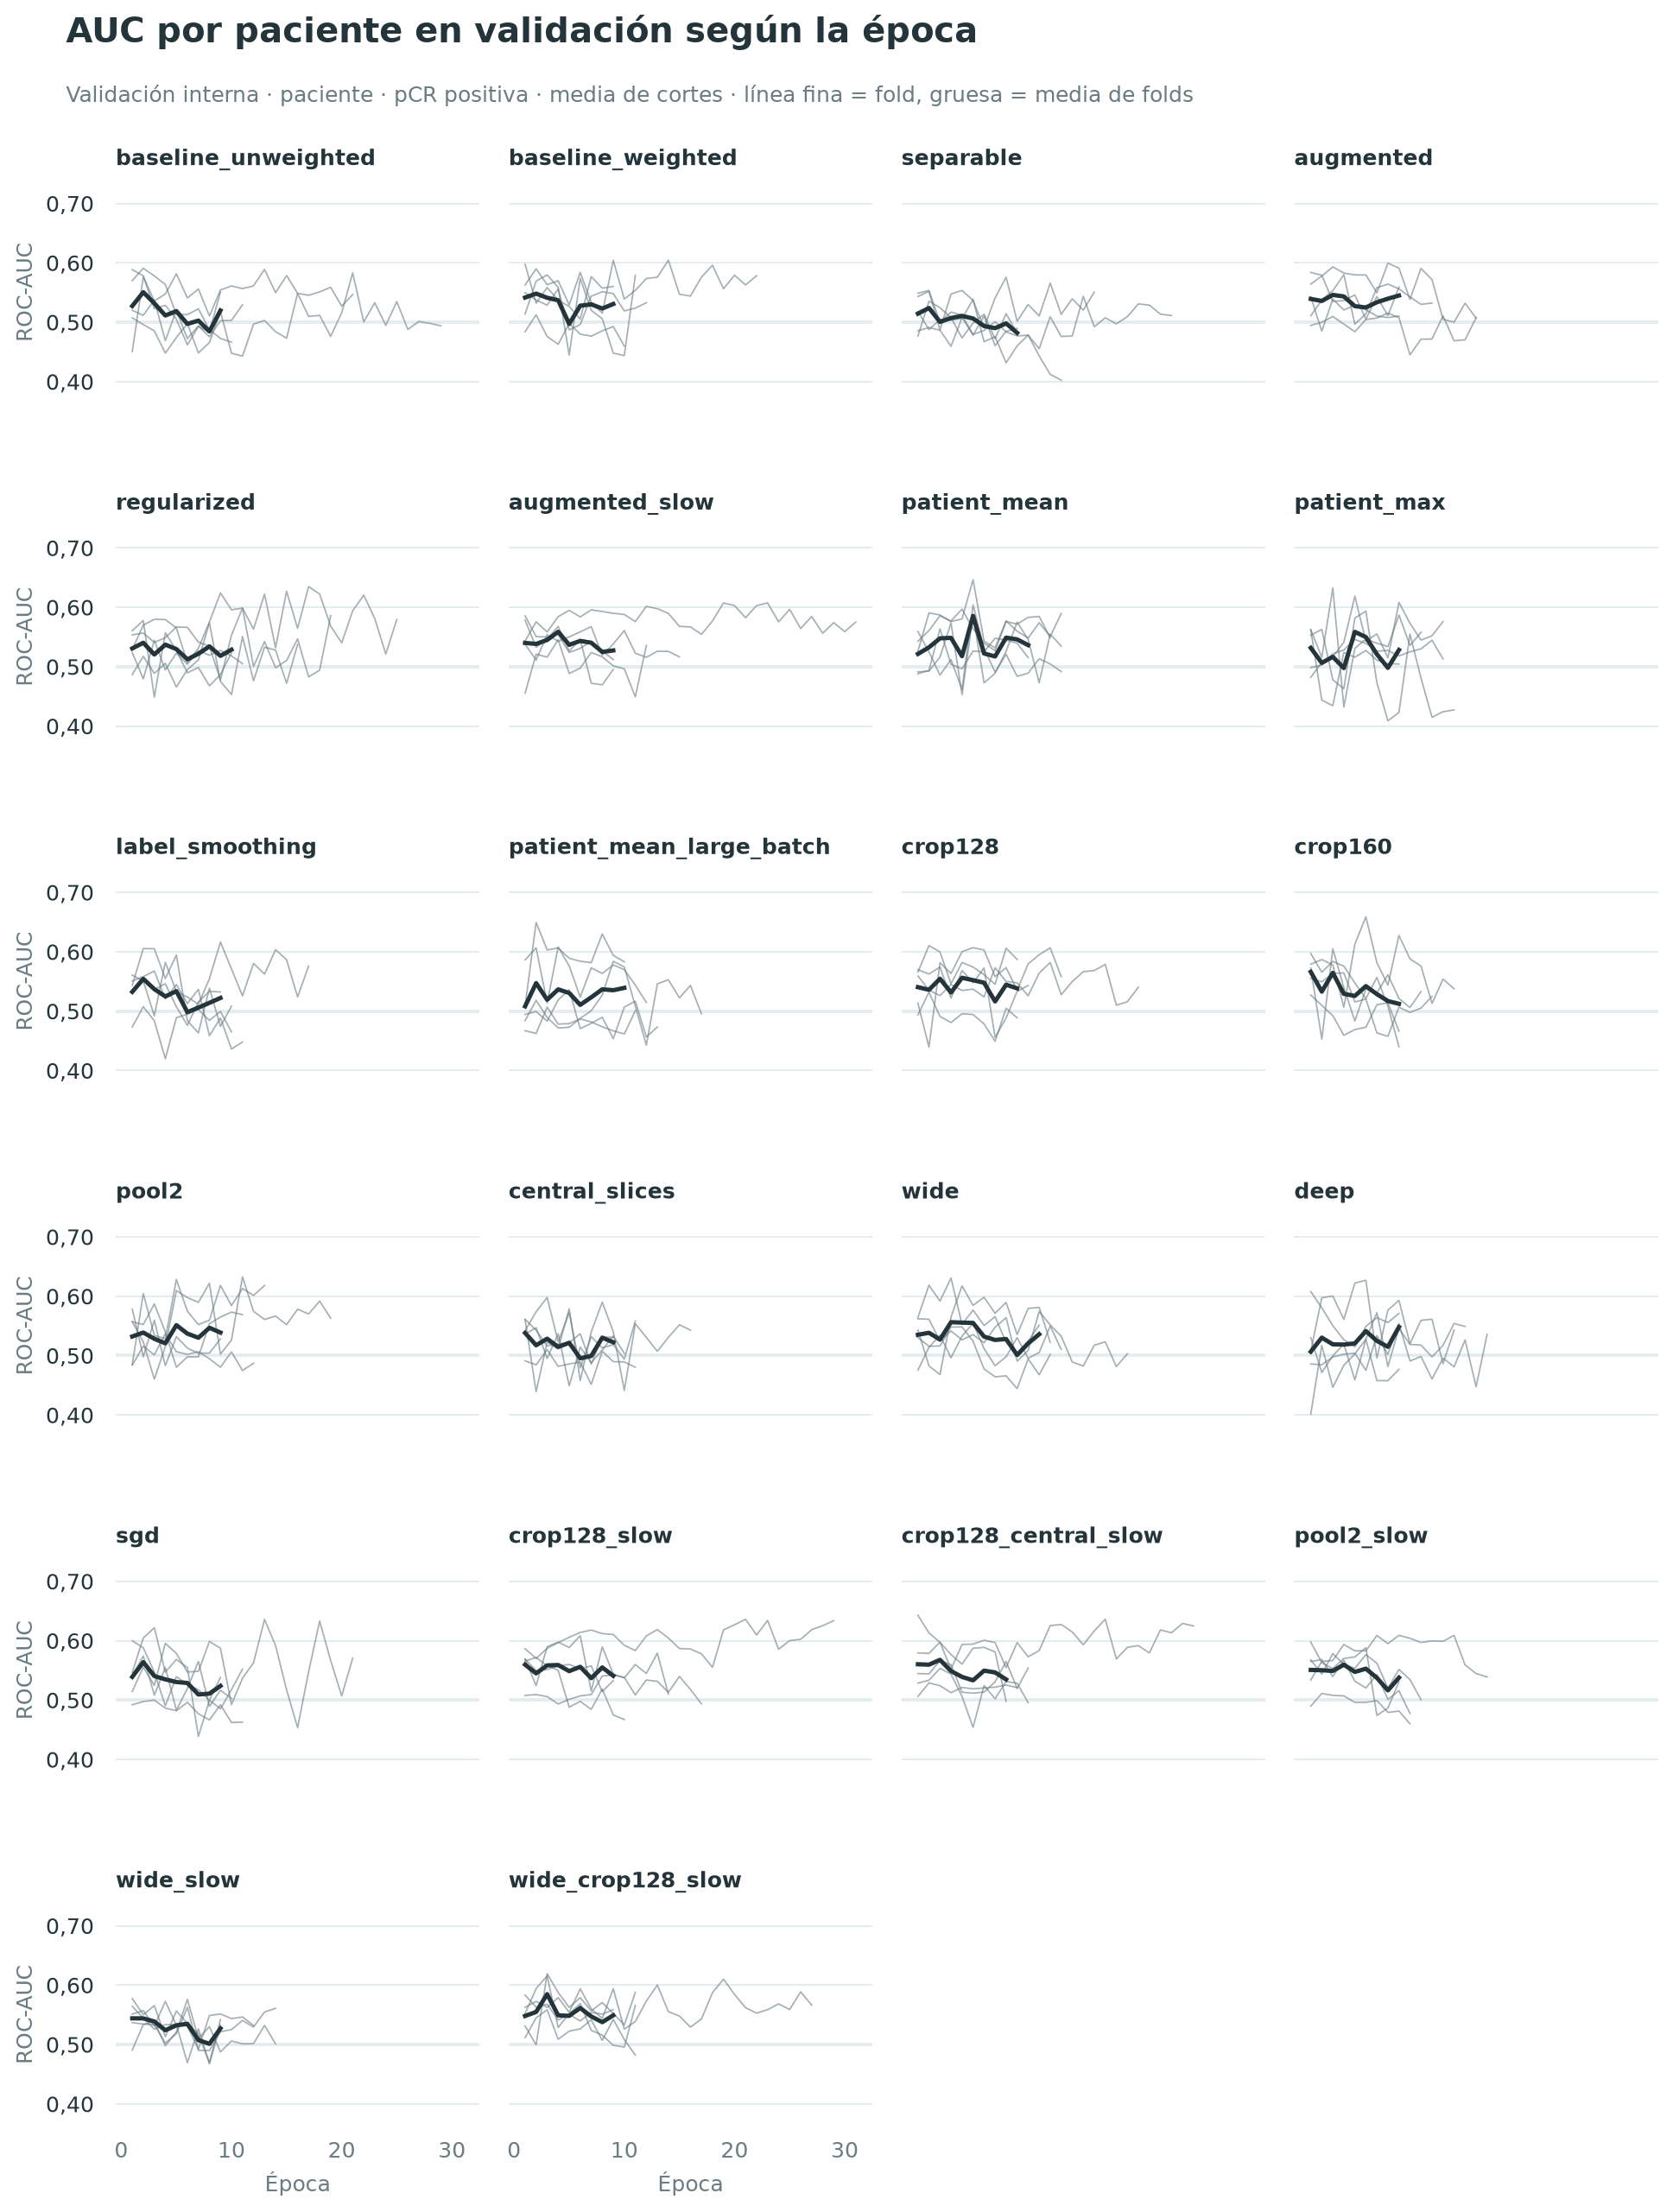

In [2]:
show(plot_validation_curves(runs), "learning_curves_validation_patient")

## Selección de época sin el fold evaluado

Durante el entrenamiento se guarda la época con mayor AUC en el propio fold de validación. Esa cifra es optimista: el máximo de una curva ruidosa supera su valor esperado aunque el modelo no tenga capacidad discriminativa. Se comparan tres reglas calculadas desde `history.csv`:

- **Mejor época del propio fold**: la regla del entrenamiento; sesgada al alza.
- **Media de todas las épocas**: no selecciona ninguna época; describe el nivel medio de la curva.
- **Época elegida con los otros folds**: para cada fold se toma la época que maximiza la curva media de los otros cuatro y se lee el AUC del fold evaluado en esa época. La decisión no utiliza las pacientes que se evalúan, por lo que es una estimación honesta del procedimiento «entrenar un número fijo de épocas».

Limitación: los candidatos se restringen a las épocas alcanzadas por todos los folds, y la parada temprana que fija esa longitud sí observó cada fold.

In [3]:
summary = selection_summary(runs)
display(summary.sort_values("out_of_fold_mean", ascending=False).round(3))

,best_mean,best_std,all_epochs_mean,all_epochs_std,out_of_fold_mean,out_of_fold_std,out_of_fold_epochs
experiment,,,,,,,
patient_mean,0.600,0.030,0.538,0.028,0.585,0.045,"[6, 6, 6, 6, 6]"
wide_crop128_slow,0.597,0.026,0.551,0.017,0.585,0.030,"[3, 3, 3, 3, 3]"
crop128_central_slow,0.586,0.051,0.551,0.037,0.568,0.031,"[3, 3, 3, 3, 3]"
sgd,0.586,0.054,0.528,0.027,0.564,0.041,"[2, 2, 2, 2, 2]"
crop160,0.590,0.049,0.532,0.031,0.556,0.037,"[1, 3, 1, 3, 1]"
label_smoothing,0.572,0.043,0.523,0.028,0.554,0.035,"[2, 2, 2, 2, 2]"
augmented_slow,0.577,0.023,0.538,0.028,0.540,0.041,"[4, 4, 7, 4, 4]"
pool2_slow,0.573,0.038,0.541,0.032,0.538,0.026,"[6, 4, 4, 4, 1]"
patient_mean_large_batch,0.577,0.057,0.528,0.049,0.534,0.060,"[2, 2, 10, 2, 2]"


## Línea base de cohorte

Las pacientes proceden de tres cohortes: Duke (un hospital) e I-SPY1 e I-SPY2 (dos ensayos clínicos multicéntricos). Cada cohorte tiene una proporción de pCR distinta, porque difieren los tratamientos y los criterios de inclusión, y también difieren los equipos y protocolos de adquisición de la resonancia. Un modelo puede, por tanto, obtener AUC superior a 0,5 reconociendo de qué cohorte procede la imagen, sin aprender nada sobre la respuesta al tratamiento.

La línea base asigna a cada paciente de validación la proporción de pCR de su cohorte en los otros cuatro folds. Su AUC mide cuánta discriminación se obtiene solo con la identidad de la cohorte.

In [4]:
scores["cohort_baseline"] = cohort_baseline(scores)
columns = [*experiments, "cohort_baseline"]
folds = fold_auc(scores, columns)
observed = folds.mean()
display(
    folds.T.assign(mean=observed, std=folds.std()).sort_values("mean", ascending=False).round(3)
)

fold,0,1,2,3,4,mean,std
patient_mean,0.597,0.587,0.646,0.564,0.604,0.600,0.030
wide_crop128_slow,0.583,0.616,0.619,0.558,0.610,0.597,0.026
pool2,0.587,0.578,0.632,0.537,0.628,0.593,0.039
patient_max,0.594,0.619,0.632,0.546,0.562,0.591,0.037
crop160,0.564,0.597,0.605,0.527,0.659,0.590,0.049
sgd,0.574,0.600,0.622,0.500,0.636,0.586,0.054
regularized,0.578,0.545,0.599,0.574,0.635,0.586,0.033
crop128_central_slow,0.553,0.566,0.643,0.529,0.636,0.586,0.051
crop128_slow,0.572,0.569,0.608,0.542,0.636,0.585,0.037
wide,0.617,0.548,0.631,0.554,0.574,0.585,0.037


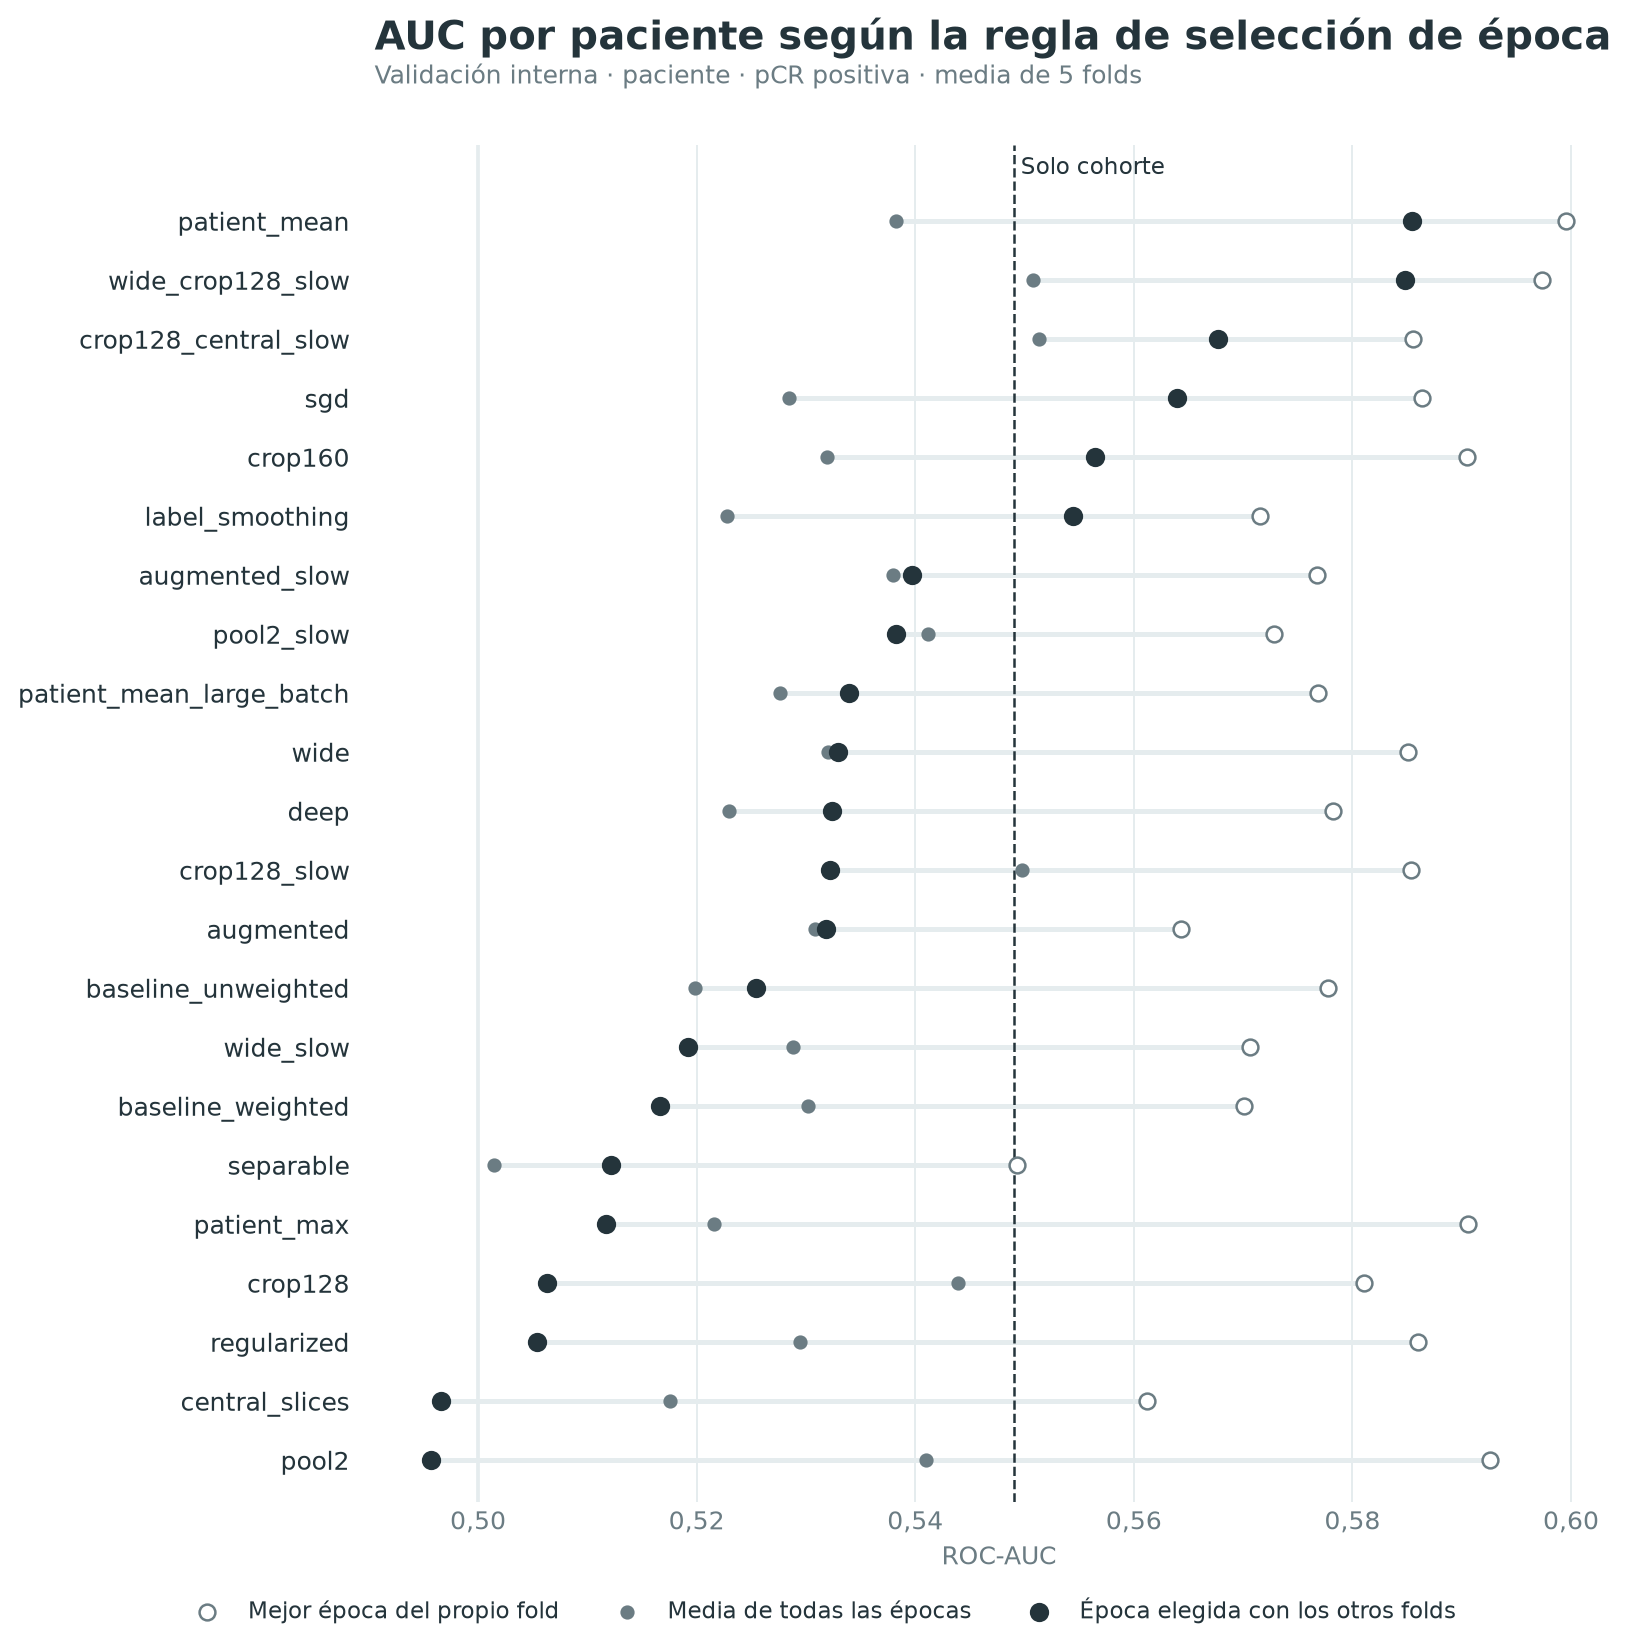

In [5]:
show(
    plot_selection_rules(summary, observed["cohort_baseline"]),
    "auc_by_epoch_selection_validation_patient",
)

## AUC por cohorte

El AUC dentro de cada cohorte compara solo pacientes de la misma cohorte, de modo que la identidad de la cohorte deja de aportar discriminación. Un valor cercano a 0,5 en las tres cohortes indicaría que el AUC global se explica por la cohorte.

Se agrupan las pacientes de validación de los cinco folds, porque I-SPY1 tiene entre 3 y 7 pacientes con pCR por fold. Al mezclar probabilidades de cinco modelos distintos, el AUC agrupado puede ser menor que la media por fold si las escalas de probabilidad difieren entre folds. Las probabilidades proceden de la mejor época del propio fold y heredan su optimismo. La línea base de cohorte no se incluye porque es constante dentro de cada cohorte.

In [6]:
counts = scores.groupby("cohort")["label"].agg(patients="size", pcr="sum")
display(counts)
display(cohort_auc(scores, experiments).T.round(3))

,patients,pcr
cohort,,
duke,209,44
spy1,104,26
spy2,784,252


cohort,duke,spy1,spy2
baseline_unweighted,0.495,0.626,0.529
baseline_weighted,0.512,0.651,0.520
separable,0.479,0.547,0.555
augmented,0.498,0.615,0.553
regularized,0.536,0.506,0.568
augmented_slow,0.584,0.641,0.540
patient_mean,0.517,0.566,0.577
patient_max,0.617,0.597,0.576
label_smoothing,0.496,0.615,0.554
patient_mean_large_batch,0.495,0.529,0.540


## Comparación emparejada mediante bootstrap

Las diferencias entre experimentos son del mismo orden que la variabilidad entre folds, por lo que se estima su incertidumbre con un bootstrap emparejado:

1. Se remuestrean pacientes con reemplazo dentro de cada estrato fold × cohorte × clase, de forma que cada réplica conserva el número de pacientes de cada combinación.
2. En cada réplica se calcula, para cada experimento y la línea base, la media de los AUC por fold, como en `metrics.json`.
3. La misma réplica se aplica a todos los experimentos; la diferencia con la referencia elimina la variación debida a qué pacientes forman la muestra, que es común a ambos.

Se informa la diferencia observada, el intervalo de percentiles y la fracción de réplicas en que el experimento no supera a la referencia.

Advertencias:

- Las predicciones guardadas corresponden a la mejor época de cada fold, de modo que todos los experimentos comparten el sesgo optimista de esa selección; el bootstrap no lo corrige.
- El bootstrap solo representa la variación por muestreo de pacientes, no la debida a la semilla ni al reparto en folds.
- Hay más de 20 comparaciones sin corrección por comparaciones múltiples: alguna diferencia aislada puede excluir el cero por azar.

In [7]:
resamples = bootstrap_auc(
    scores,
    columns,
    analysis_config.bootstrap_strata,
    n_resamples=analysis_config.bootstrap_resamples,
    seed=analysis_config.seed,
)
differences = paired_differences(
    observed, resamples, analysis_config.reference, analysis_config.confidence_level
)
display(differences.sort_values("difference", ascending=False).round(3))

,difference,lower,upper,p_not_better
patient_mean,0.014,-0.031,0.061,0.264
wide_crop128_slow,0.012,-0.022,0.046,0.253
pool2,0.007,-0.030,0.045,0.345
patient_max,0.005,-0.035,0.046,0.396
crop160,0.005,-0.025,0.035,0.372
sgd,0.001,-0.040,0.041,0.479
regularized,0.001,-0.039,0.041,0.485
crop128_central_slow,0.000,-0.025,0.026,0.493
wide,-0.000,-0.043,0.044,0.505
crop128,-0.004,-0.040,0.032,0.588


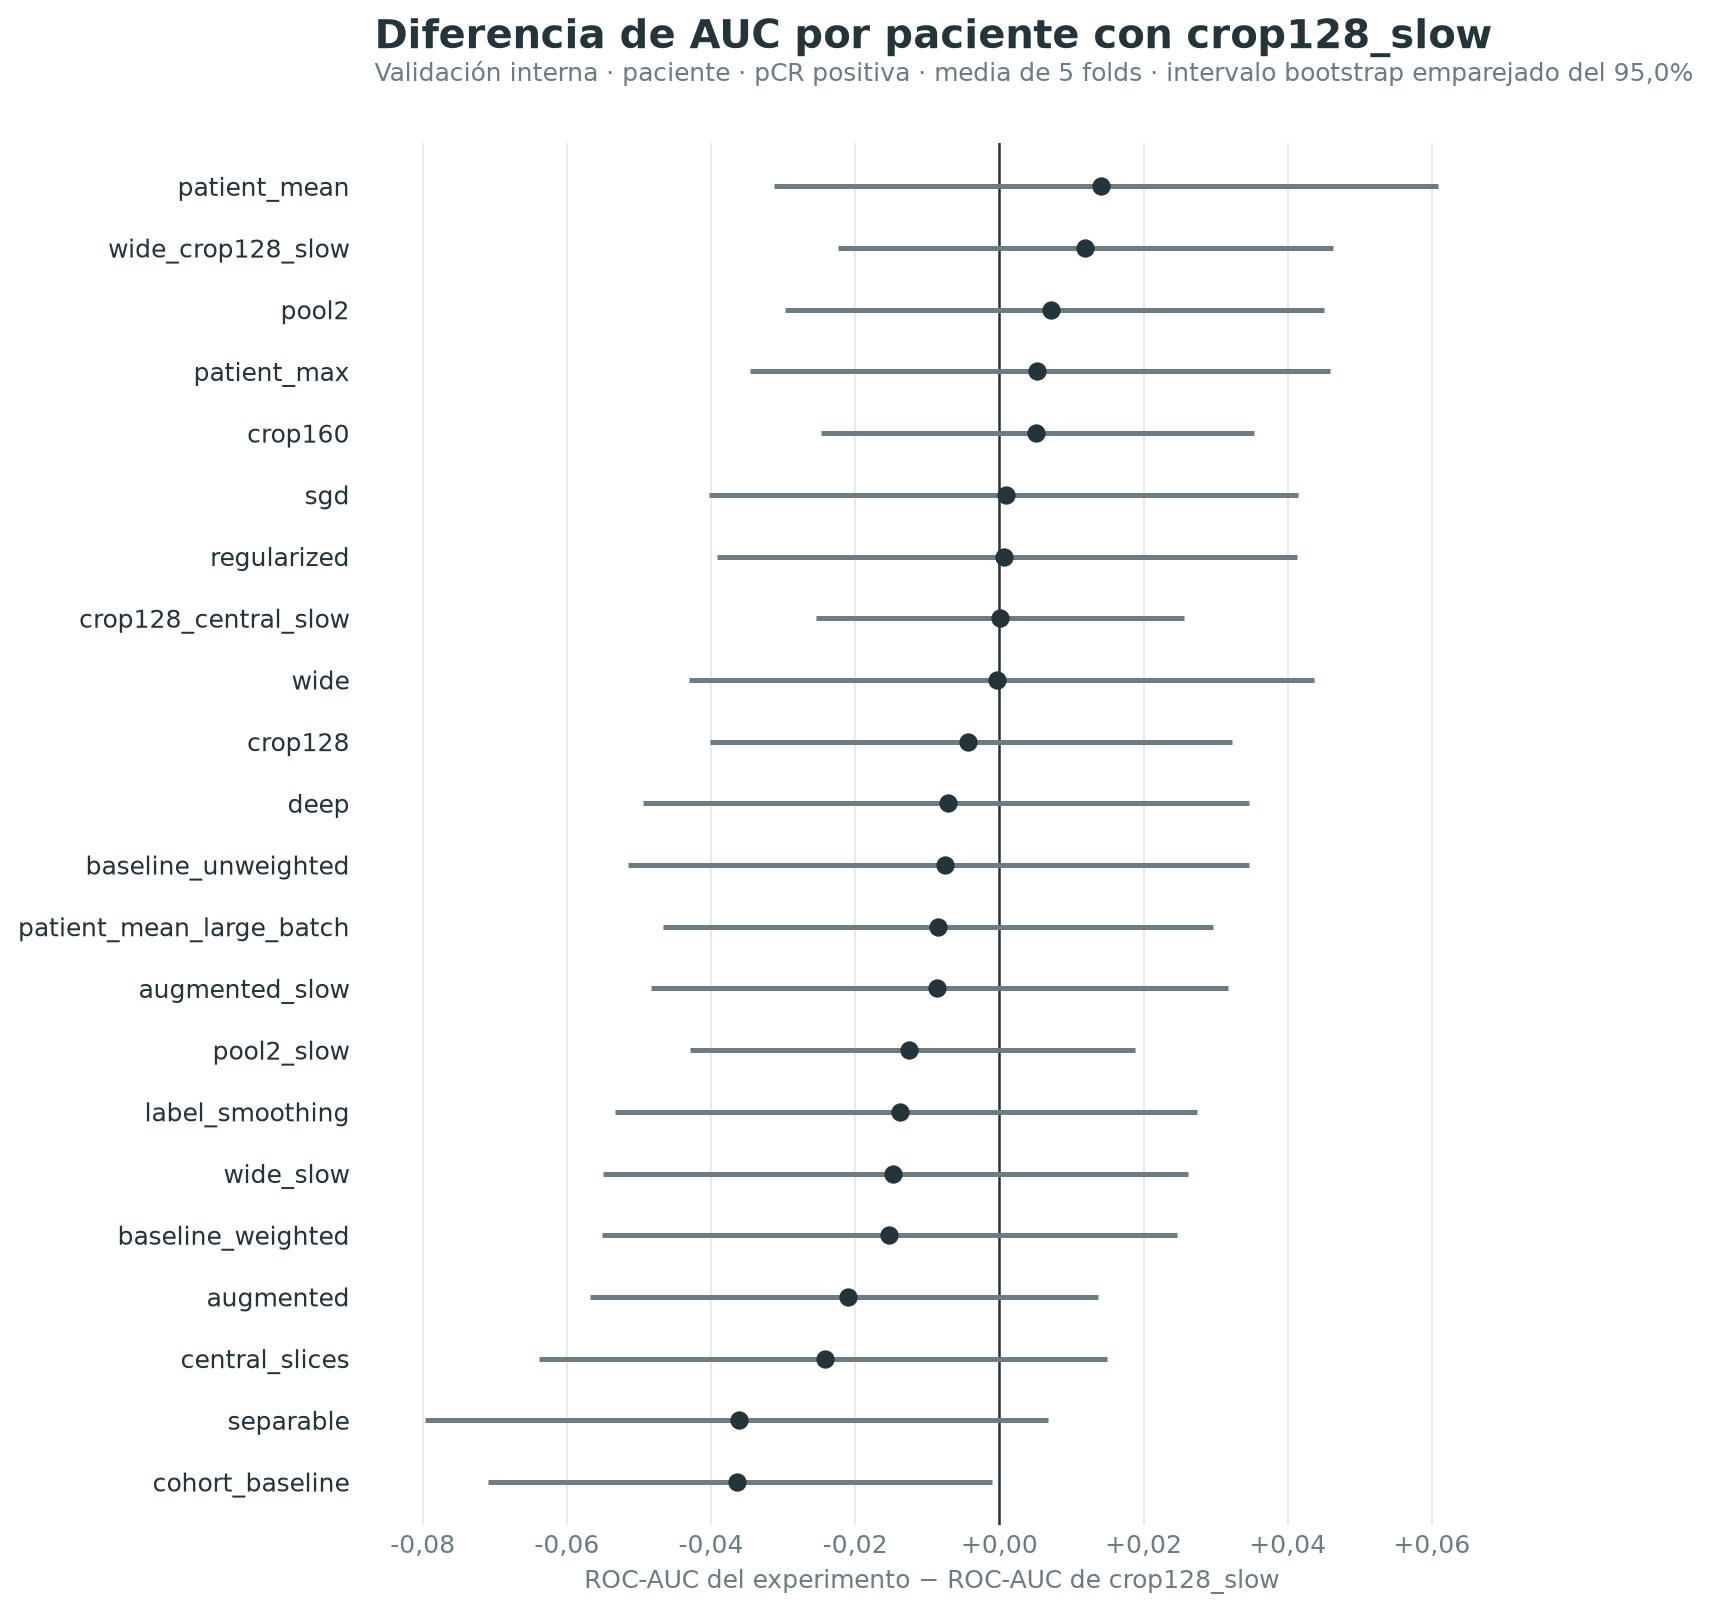

In [8]:
show(
    plot_paired_differences(
        differences, analysis_config.reference, analysis_config.confidence_level
    ),
    "auc_difference_validation_patient",
)